# 🚀 Spaceship Titanic — Transported Passenger Prediction
### End-Term Machine Learning Project

**Problem Statement:**  
Predict whether a passenger on board the Spaceship Titanic was **Transported** (True/False) to an alternate dimension following a collision with a spacetime anomaly.

**Project Architecture:**
1. **Data Loading & Inspection**
2. **Exploratory Data Analysis (EDA)**
3. **Feature Engineering** (Cabin Deck/CabinNum/Side, GroupId, GroupSize, Spend aggregates)
4. **Data Cleaning & Missing Value Imputation** (Domain-based CryoSleep logic, median & mode)
5. **Outlier Detection & Treatment (IQR Method)**
6. **Categorical Variable Encoding (LabelEncoder)**
7. **Feature Selection (SelectKBest)**
8. **Feature Scaling (MinMaxScaler) & 80/20 Train-Validation Split**
9. **Model Building & Baseline Evaluation (Random Forest vs XGBoost)**
10. **Hyperparameter Tuning (GridSearchCV)**
11. **Model Evaluation & Visualization (Confusion Matrix, ROC-AUC, Feature Importance)**
12. **Test Predictions & Kaggle Submission Generation**

---
## 1. Import Libraries & Load Data

In [1]:
# ── Standard Libraries ────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Machine Learning Libraries ────────────────────────────────────────────────
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)

# Set visual style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('tab10')
print('All libraries imported successfully! ✅')

All libraries imported successfully! ✅


In [2]:
# ── Load Training and Test Datasets ───────────────────────────────────────────
train_df = pd.read_csv('train.csv')
test_df  = pd.read_csv('test.csv')
sample_sub = pd.read_csv('sample_submission.csv')

print(f'Training Set Shape: {train_df.shape}')
print(f'Test Set Shape    : {test_df.shape}')
print(f'Sample Submission : {sample_sub.shape}')
train_df.head()

Training Set Shape: (8693, 14)
Test Set Shape    : (4277, 13)
Sample Submission : (4277, 2)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


---
## 2. Exploratory Data Analysis (EDA)

In [3]:
# ── Dataset Information & Statistical Summary ─────────────────────────────────
print('=== Data Types & Null Counts ===')
train_df.info()
print('\n=== Numerical Summary ===')
train_df.describe()

=== Data Types & Null Counts ===
<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB

=== Numerical Summary ===


,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [4]:
# ── Check and Handle Duplicate Rows ───────────────────────────────────────────
duplicates = train_df.duplicated().sum()
print(f'Number of duplicate rows in train dataset: {duplicates}')
if duplicates > 0:
    train_df.drop_duplicates(inplace=True)
    print(f'Shape after removing duplicates: {train_df.shape}')

Number of duplicate rows in train dataset: 0


Target Counts:
Transported
True     4378
False    4315
Name: count, dtype: int64


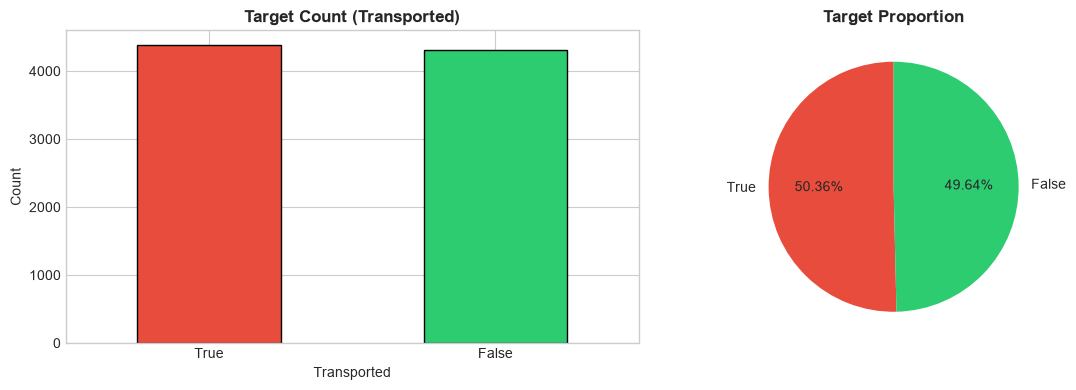

In [5]:
# ── Target Variable Analysis (Transported) ────────────────────────────────────
print('Target Counts:')
print(train_df['Transported'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df['Transported'].value_counts().plot(kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Target Count (Transported)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Transported')
axes[0].set_ylabel('Count')
axes[0].tick_params(rotation=0)

train_df['Transported'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.2f%%',
                                             colors=['#e74c3c', '#2ecc71'], startangle=90)
axes[1].set_title('Target Proportion', fontsize=12, fontweight='bold')
axes[1].set_ylabel('')
plt.tight_layout()
plt.savefig('target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

=== Missing Values Table ===
              Missing Count  Missing (%)
CryoSleep               217         2.50
ShoppingMall            208         2.39
VIP                     203         2.34
HomePlanet              201         2.31
Name                    200         2.30
Cabin                   199         2.29
VRDeck                  188         2.16
FoodCourt               183         2.11
Spa                     183         2.11
Destination             182         2.09
RoomService             181         2.08
Age                     179         2.06


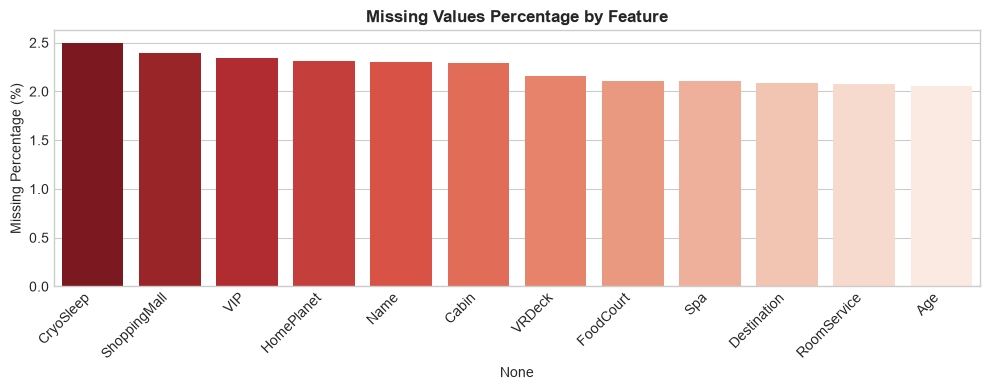

In [6]:
# ── Missing Values Analysis ───────────────────────────────────────────────────
missing_counts = train_df.isnull().sum()
missing_pct = (missing_counts / len(train_df) * 100).round(2)
missing_table = pd.DataFrame({'Missing Count': missing_counts, 'Missing (%)': missing_pct})
missing_table = missing_table[missing_table['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print('=== Missing Values Table ===')
print(missing_table)

plt.figure(figsize=(10, 4))
sns.barplot(x=missing_table.index, y=missing_table['Missing (%)'], palette='Reds_r')
plt.title('Missing Values Percentage by Feature', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Missing Percentage (%)')
plt.tight_layout()
plt.savefig('missing_values.png', dpi=120, bbox_inches='tight')
plt.show()

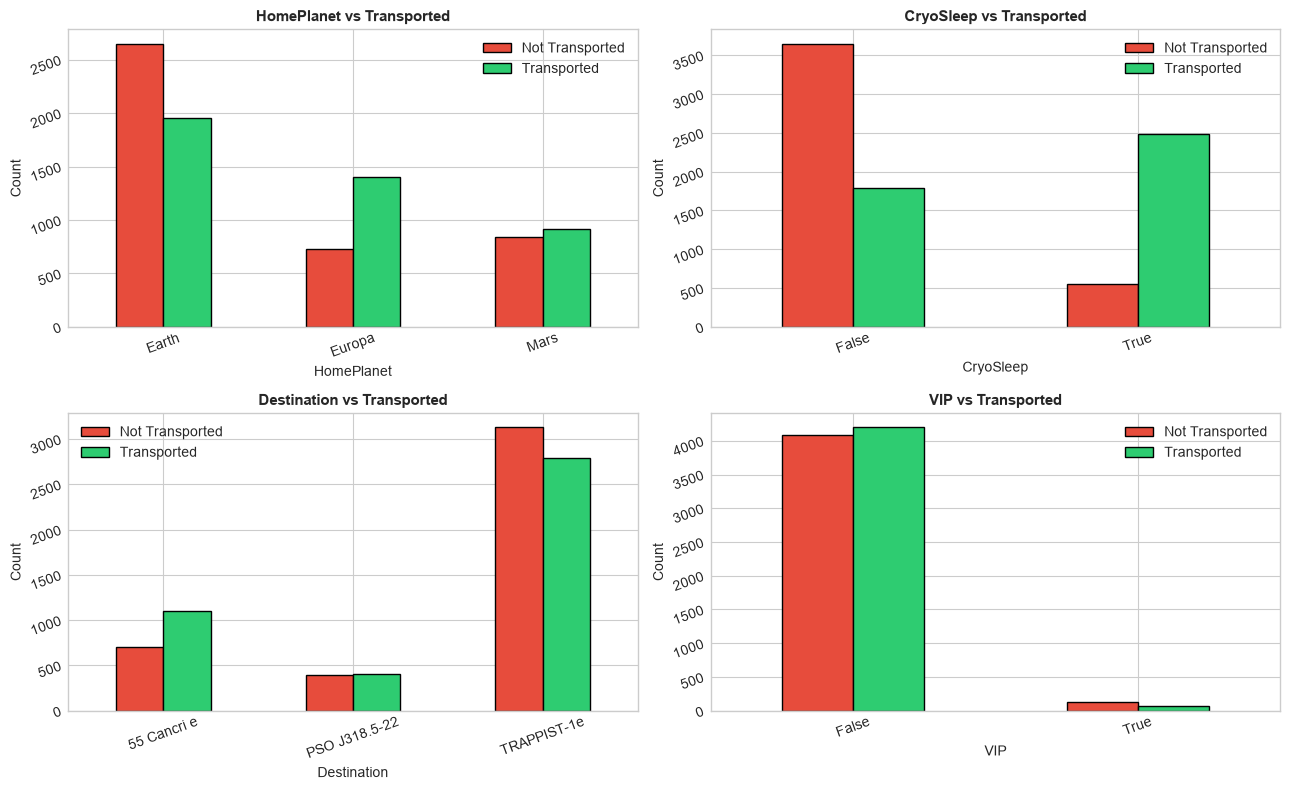

In [7]:
# ── Categorical Features vs Target ───────────────────────────────────────────
cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP']

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    ct = pd.crosstab(train_df[col].astype(str), train_df['Transported'])
    ct.plot(kind='bar', ax=axes[i], color=['#e74c3c', '#2ecc71'], edgecolor='black')
    axes[i].set_title(f'{col} vs Transported', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(rotation=20)
    axes[i].legend(['Not Transported', 'Transported'])

plt.tight_layout()
plt.savefig('categorical_vs_target.png', dpi=120, bbox_inches='tight')
plt.show()

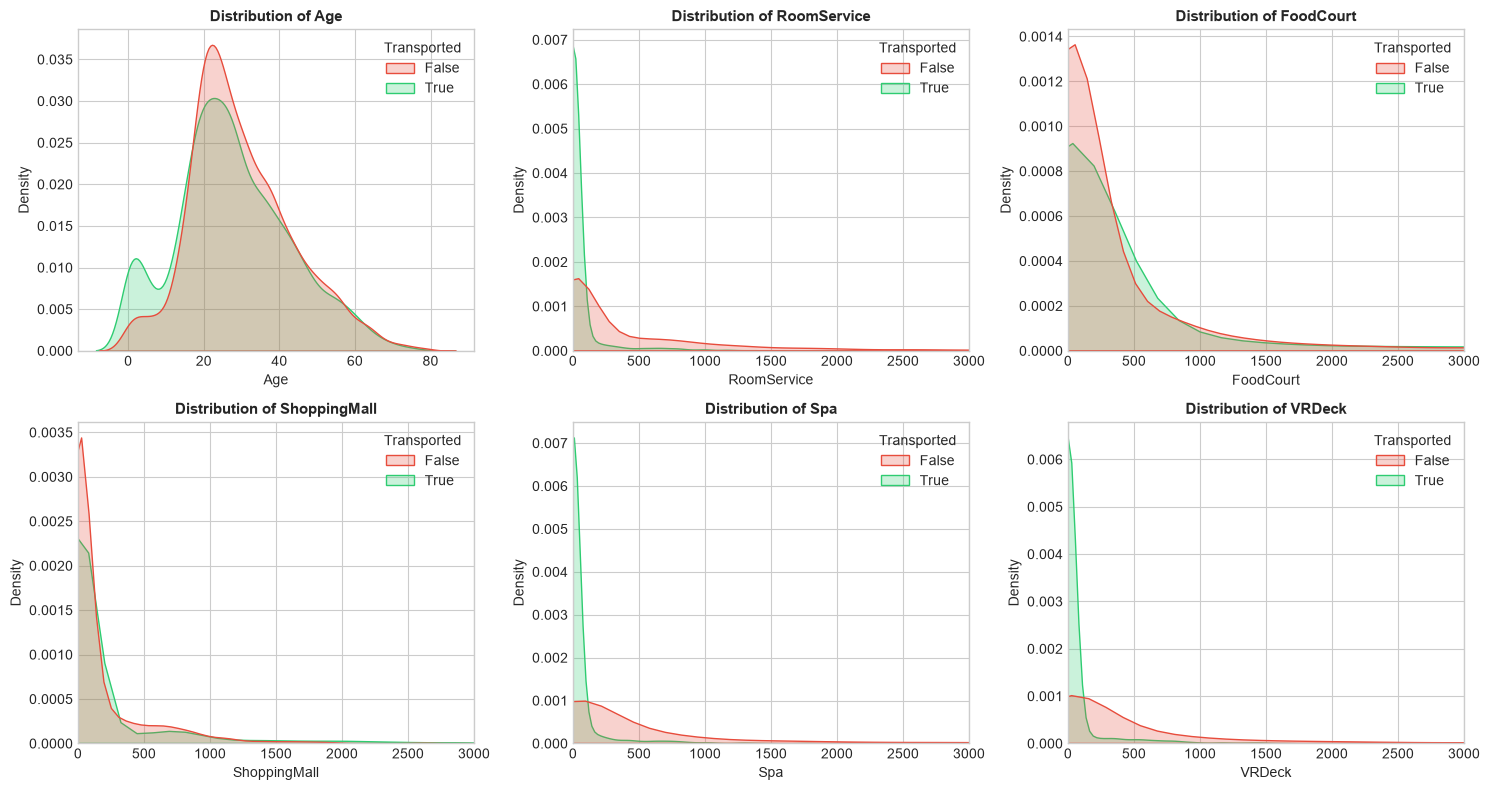

In [8]:
# ── Numerical Features Distribution by Target ─────────────────────────────────
num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.kdeplot(data=train_df, x=col, hue='Transported', ax=axes[i], fill=True, common_norm=False, palette=['#e74c3c', '#2ecc71'])
    axes[i].set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
    if col != 'Age':
        axes[i].set_xlim(0, 3000)

plt.tight_layout()
plt.savefig('numerical_distributions.png', dpi=120, bbox_inches='tight')
plt.show()

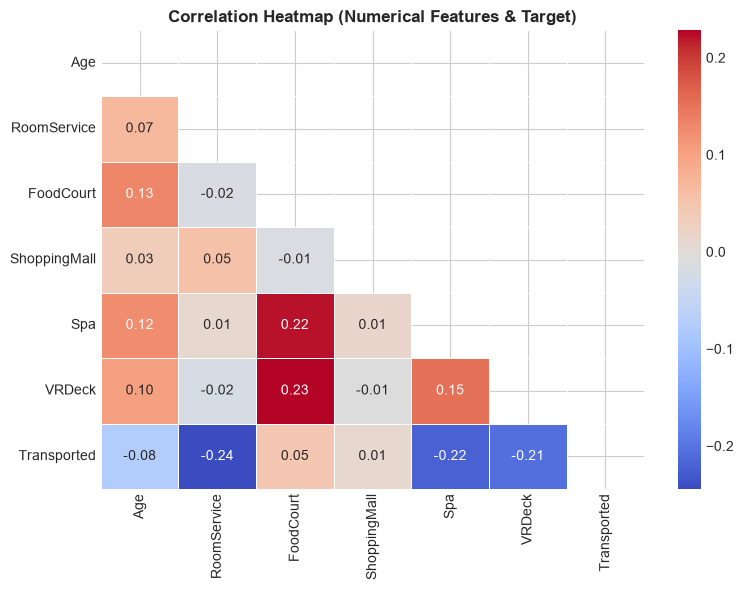

In [9]:
# ── Correlation Heatmap for Numerical Features ────────────────────────────────
corr_data = train_df[num_cols].copy()
corr_data['Transported'] = train_df['Transported'].astype(int)

plt.figure(figsize=(8, 6))
corr = corr_data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, linewidths=0.5)
plt.title('Correlation Heatmap (Numerical Features & Target)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 3. Feature Engineering

In [10]:
# ── Extract Rich Domain Features ─────────────────────────────────────────────
# 1. Cabin parsing: Deck / CabinNum / Side
# 2. PassengerId parsing: GroupId / GroupSize / IsAlone
# 3. Spend aggregations: TotalSpend, LuxurySpend (Spa + VRDeck), HasSpend

def extract_features(df):
    df = df.copy()
    
    # Cabin extraction
    cabin_split = df['Cabin'].str.split('/', expand=True)
    df['Deck'] = cabin_split[0]
    df['CabinNum'] = pd.to_numeric(cabin_split[1], errors='coerce')
    df['Side'] = cabin_split[2]
    
    # PassengerId group extraction
    df['GroupId'] = df['PassengerId'].str.split('_').str[0]
    df['GroupSize'] = df.groupby('GroupId')['PassengerId'].transform('count')
    df['IsAlone'] = (df['GroupSize'] == 1).astype(int)
    
    # Spend aggregations
    spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    df['TotalSpend']  = df[spend_cols].sum(axis=1)
    df['LuxurySpend'] = df['Spa'] + df['VRDeck']
    df['HasSpend']    = (df['TotalSpend'] > 0).astype(int)
    return df

train_df = extract_features(train_df)
test_df  = extract_features(test_df)

print('Extracted Features Sample:')
train_df[['Deck', 'CabinNum', 'Side', 'GroupId', 'GroupSize', 'IsAlone', 'TotalSpend', 'LuxurySpend', 'HasSpend']].head()

Extracted Features Sample:


,Deck,CabinNum,Side,GroupId,GroupSize,IsAlone,TotalSpend,LuxurySpend,HasSpend
0,B,0.0,P,0001,1,1,0.0,0.0,0
1,F,0.0,S,0002,1,1,736.0,593.0,1
2,A,0.0,S,0003,2,0,10383.0,6764.0,1
3,A,0.0,S,0003,2,0,5176.0,3522.0,1
4,F,1.0,S,0004,1,1,1091.0,567.0,1


---
## 4. Data Cleaning & Missing Value Imputation

In [11]:
# ── Domain-Specific Missing Value Imputation ──────────────────────────────────
# Logic:
# 1. If CryoSleep is True, passenger spends 0 on amenities.
# 2. For remaining missing spend, age and cabin number: fill with median.
# 3. For categorical features (HomePlanet, Destination, Deck, Side): fill with mode.

def impute_missing(df):
    df = df.copy()
    
    # Standardize boolean columns
    for col in ['CryoSleep', 'VIP']:
        df[col] = df[col].map({'True': True, 'False': False, True: True, False: False})
        df[col] = df[col].fillna(df[col].mode()[0]).astype(int)
        
    # Categorical mode imputation
    for col in ['HomePlanet', 'Destination', 'Deck', 'Side']:
        df[col] = df[col].fillna(df[col].mode()[0])
        
    # CryoSleep spending logic + median imputation
    spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    for col in spend_cols:
        cryo_mask = (df['CryoSleep'] == 1)
        df.loc[cryo_mask, col] = df.loc[cryo_mask, col].fillna(0)
        df[col] = df[col].fillna(df[col].median())
        
    # Recalculate spend features after imputation
    df['TotalSpend']  = df[spend_cols].sum(axis=1)
    df['LuxurySpend'] = df['Spa'] + df['VRDeck']
    df['HasSpend']    = (df['TotalSpend'] > 0).astype(int)
    
    # Numerical features
    df['Age'] = df['Age'].fillna(df['Age'].median())
    df['CabinNum'] = df['CabinNum'].fillna(df['CabinNum'].median())
    
    # Age groups
    df['AgeGroup'] = pd.cut(df['Age'], bins=[-1, 12, 18, 35, 60, 100],
                            labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'])
    return df

train_df = impute_missing(train_df)
test_df  = impute_missing(test_df)

print('Missing values in train after cleaning:')
print(train_df[['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'Deck', 'CabinNum', 'Side', 'TotalSpend']].isnull().sum())

Missing values in train after cleaning:
HomePlanet     0
CryoSleep      0
Destination    0
Age            0
VIP            0
Deck           0
CabinNum       0
Side           0
TotalSpend     0
dtype: int64


---
## 5. Outlier Detection & Treatment (IQR Method)

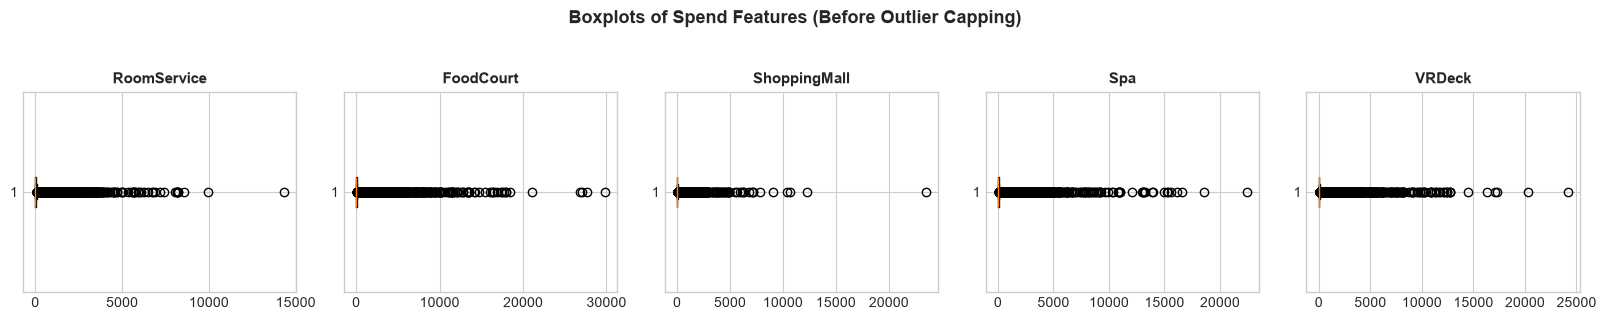

In [12]:
# ── Boxplots Before Outlier Treatment ─────────────────────────────────────────
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for i, col in enumerate(spend_cols):
    axes[i].boxplot(train_df[col], vert=False, patch_artist=True, boxprops=dict(facecolor='#3498db'))
    axes[i].set_title(col, fontsize=11, fontweight='bold')

plt.suptitle('Boxplots of Spend Features (Before Outlier Capping)', fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('boxplots_before.png', dpi=120, bbox_inches='tight')
plt.show()

RoomService     -> Q1: 0.0, Q3: 41.0, Upper Fence: 164.0
FoodCourt       -> Q1: 0.0, Q3: 61.0, Upper Fence: 244.0
ShoppingMall    -> Q1: 0.0, Q3: 22.0, Upper Fence: 88.0
Spa             -> Q1: 0.0, Q3: 53.0, Upper Fence: 212.0
VRDeck          -> Q1: 0.0, Q3: 40.0, Upper Fence: 160.0


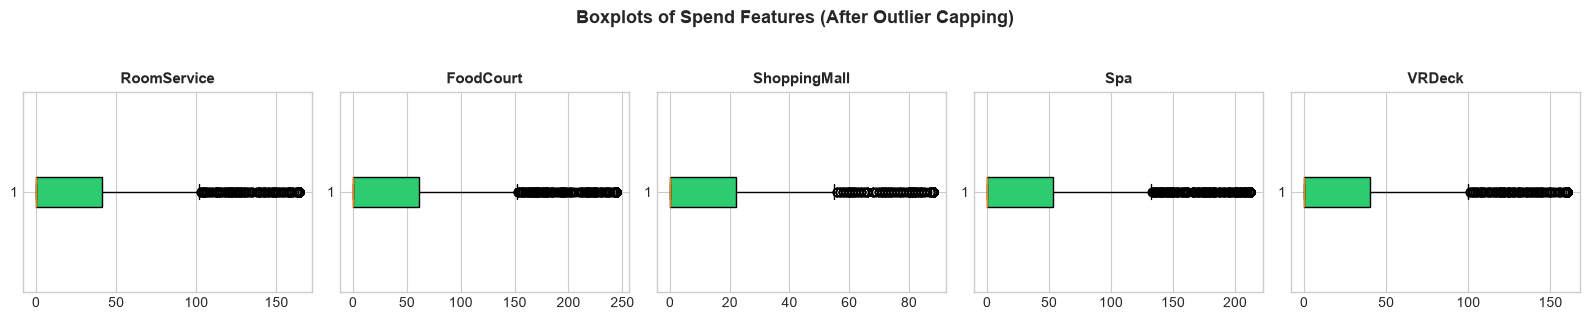

In [13]:
# ── Outlier Capping (Winsorization using IQR method) ───────────────────────────
# Rather than dropping rows (which would lose valuable training samples and cannot be done on test),
# we cap values at Q3 + 3.0 * IQR to retain predictive signal while suppressing extreme outliers.

for col in spend_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 3.0 * iqr
    
    # Apply capping to train and test
    train_df[col] = train_df[col].clip(upper=upper_fence)
    test_df[col]  = test_df[col].clip(upper=upper_fence)
    print(f'{col:15s} -> Q1: {q1:.1f}, Q3: {q3:.1f}, Upper Fence: {upper_fence:.1f}')

# Boxplots after capping
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for i, col in enumerate(spend_cols):
    axes[i].boxplot(train_df[col], vert=False, patch_artist=True, boxprops=dict(facecolor='#2ecc71'))
    axes[i].set_title(col, fontsize=11, fontweight='bold')

plt.suptitle('Boxplots of Spend Features (After Outlier Capping)', fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('boxplots_after.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 6. Categorical Variable Encoding

In [14]:
# ── Encode Categorical Variables using LabelEncoder ───────────────────────────
cat_encode_cols = ['HomePlanet', 'Destination', 'Deck', 'Side', 'AgeGroup']

for col in cat_encode_cols:
    le = LabelEncoder()
    combined = pd.concat([train_df[col], test_df[col]]).astype(str)
    le.fit(combined)
    train_df[col] = le.transform(train_df[col].astype(str))
    test_df[col]  = le.transform(test_df[col].astype(str))

# Define final list of features
drop_cols = ['PassengerId', 'Name', 'Cabin', 'GroupId', 'Transported']
feature_cols = [c for c in train_df.columns if c not in drop_cols]

X = train_df[feature_cols].copy()
y = train_df['Transported'].astype(int)
X_test = test_df[feature_cols].copy()

print(f'Total Features: {len(feature_cols)}')
print('Features:', feature_cols)
X.head()

Total Features: 19
Features: ['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Deck', 'CabinNum', 'Side', 'GroupSize', 'IsAlone', 'TotalSpend', 'LuxurySpend', 'HasSpend', 'AgeGroup']


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNum,Side,GroupSize,IsAlone,TotalSpend,LuxurySpend,HasSpend,AgeGroup
0,1,0,2,39.0,0,0.0,0.0,0.0,0.0,0.0,1,0.0,0,1,1,0.0,0.0,0,0
1,0,0,2,24.0,0,109.0,9.0,25.0,212.0,44.0,5,0.0,1,1,1,736.0,593.0,1,4
2,1,0,2,58.0,1,43.0,244.0,0.0,212.0,49.0,0,0.0,1,2,0,10383.0,6764.0,1,0
3,1,0,2,33.0,0,0.0,244.0,88.0,212.0,160.0,0,0.0,1,2,0,5176.0,3522.0,1,4
4,0,0,2,16.0,0,164.0,70.0,88.0,212.0,2.0,5,1.0,1,1,1,1091.0,567.0,1,3


---
## 7. Feature Selection (SelectKBest)

=== Feature Importance Ranking (F-Score) ===
         Feature      F-Score        p-value
0       HasSpend  2624.905213   0.000000e+00
1      CryoSleep  2334.295199   0.000000e+00
2            Spa  1095.154418  2.694252e-226
3    RoomService  1083.950392  3.929294e-224
4         VRDeck   941.560620  2.063952e-196
5    LuxurySpend   736.150287  1.103949e-155
6     TotalSpend   360.295256   9.382847e-79
7   ShoppingMall   266.447853   5.067999e-59
8     HomePlanet   117.427316   3.451795e-27
9           Deck   116.358176   5.875592e-27
10       IsAlone   114.011986   1.888636e-26
11     FoodCourt   106.569775   7.694363e-25
12   Destination   102.861127   4.890657e-24
13          Side    90.284121   2.617375e-21
14     GroupSize    59.768286   1.186047e-14
15           Age    48.156922   4.216286e-12
16      AgeGroup    18.232913   1.975502e-05
17      CabinNum    17.246008   3.315266e-05
18           VIP    12.083096   5.112961e-04


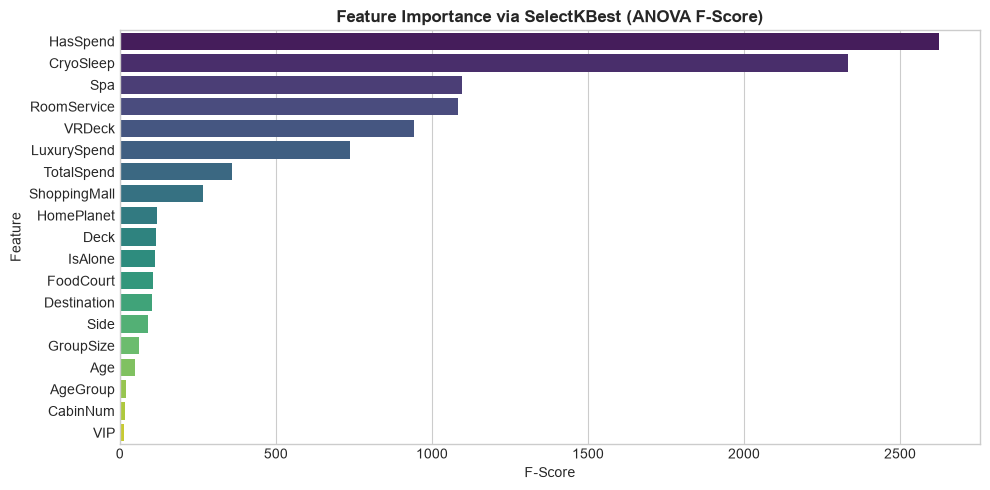

In [15]:
# ── SelectKBest Feature Selection (ANOVA F-Classification) ─────────────────────
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X, y)

feature_scores = pd.DataFrame({
    'Feature': feature_cols,
    'F-Score': selector.scores_,
    'p-value': selector.pvalues_
}).sort_values(by='F-Score', ascending=False).reset_index(drop=True)

print('=== Feature Importance Ranking (F-Score) ===')
print(feature_scores)

plt.figure(figsize=(10, 5))
sns.barplot(data=feature_scores, x='F-Score', y='Feature', palette='viridis')
plt.title('Feature Importance via SelectKBest (ANOVA F-Score)', fontsize=12, fontweight='bold')
plt.xlabel('F-Score')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 8. Feature Scaling (MinMaxScaler) & Train-Validation Split

In [16]:
# ── MinMax Scaling ────────────────────────────────────────────────────────────
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

# 80/20 Stratified Train-Validation Split
X_train, X_val, y_train, y_val = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set size   : {X_train.shape[0]} samples')
print(f'Validation set size : {X_val.shape[0]} samples')
print(f'Target balance in train: {y_train.mean():.2%}')
X_scaled.describe().loc[['min', 'max']]

Training set size   : 6954 samples
Validation set size : 1739 samples
Target balance in train: 50.36%


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNum,Side,GroupSize,IsAlone,TotalSpend,LuxurySpend,HasSpend,AgeGroup
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


---
## 9. Baseline Model Training (Random Forest vs XGBoost)

In [17]:
# ── Baseline Random Forest ───────────────────────────────────────────────────
rf_base = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)
rf_base_pred = rf_base.predict(X_val)
rf_base_acc = accuracy_score(y_val, rf_base_pred)

# ── Baseline XGBoost ─────────────────────────────────────────────────────────
xgb_base = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
xgb_base.fit(X_train, y_train)
xgb_base_pred = xgb_base.predict(X_val)
xgb_base_acc = accuracy_score(y_val, xgb_base_pred)

print(f'Baseline Random Forest Accuracy : {rf_base_acc:.4f} ({rf_base_acc*100:.2f}%)')
print(f'Baseline XGBoost Accuracy       : {xgb_base_acc:.4f} ({xgb_base_acc*100:.2f}%)')

Baseline Random Forest Accuracy : 0.7964 (79.64%)
Baseline XGBoost Accuracy       : 0.8045 (80.45%)


---
## 10. Hyperparameter Tuning using GridSearchCV

In [18]:
# ── Hyperparameter Tuning: Random Forest (GridSearchCV) ────────────────────────
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [8, 12, 16],
    'min_samples_split': [2, 5]
}

print('Running GridSearchCV for Random Forest...')
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_
rf_tuned_pred = best_rf.predict(X_val)
rf_tuned_acc = accuracy_score(y_val, rf_tuned_pred)

print(f'Best RF Parameters   : {rf_grid.best_params_}')
print(f'Best RF CV Score     : {rf_grid.best_score_:.4f}')
print(f'Tuned RF Val Accuracy: {rf_tuned_acc:.4f} ({rf_tuned_acc*100:.2f}%)')

Running GridSearchCV for Random Forest...


Best RF Parameters   : {'max_depth': 12, 'min_samples_split': 2, 'n_estimators': 100}
Best RF CV Score     : 0.7977
Tuned RF Val Accuracy: 0.8033 (80.33%)


In [19]:
# ── Hyperparameter Tuning: XGBoost (GridSearchCV) ─────────────────────────────
xgb_param_grid = {
    'n_estimators': [150, 250],
    'max_depth': [4, 6],
    'learning_rate': [0.03, 0.08]
}

print('Running GridSearchCV for XGBoost...')
xgb_grid = GridSearchCV(
    estimator=XGBClassifier(eval_metric='logloss', random_state=42),
    param_grid=xgb_param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
xgb_grid.fit(X_train, y_train)

best_xgb = xgb_grid.best_estimator_
xgb_tuned_pred = best_xgb.predict(X_val)
xgb_tuned_acc = accuracy_score(y_val, xgb_tuned_pred)

print(f'Best XGBoost Parameters   : {xgb_grid.best_params_}')
print(f'Best XGBoost CV Score     : {xgb_grid.best_score_:.4f}')
print(f'Tuned XGBoost Val Accuracy: {xgb_tuned_acc:.4f} ({xgb_tuned_acc*100:.2f}%)')

Running GridSearchCV for XGBoost...


Best XGBoost Parameters   : {'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 250}
Best XGBoost CV Score     : 0.8050
Tuned XGBoost Val Accuracy: 0.8125 (81.25%)


---
## 11. Model Evaluation & Comparison

In [20]:
# ── Performance Summary Table ─────────────────────────────────────────────────
results_df = pd.DataFrame({
    'Model': ['Baseline Random Forest', 'Tuned Random Forest', 'Baseline XGBoost', 'Tuned XGBoost'],
    'Validation Accuracy': [rf_base_acc, rf_tuned_acc, xgb_base_acc, xgb_tuned_acc],
    'ROC-AUC Score': [
        roc_auc_score(y_val, rf_base.predict_proba(X_val)[:, 1]),
        roc_auc_score(y_val, best_rf.predict_proba(X_val)[:, 1]),
        roc_auc_score(y_val, xgb_base.predict_proba(X_val)[:, 1]),
        roc_auc_score(y_val, best_xgb.predict_proba(X_val)[:, 1])
    ]
})
results_df['Validation Accuracy'] = results_df['Validation Accuracy'].round(4)
results_df['ROC-AUC Score'] = results_df['ROC-AUC Score'].round(4)

print('=== Model Performance Comparison ===')
print(results_df.to_string(index=False))
results_df

=== Model Performance Comparison ===
                 Model  Validation Accuracy  ROC-AUC Score
Baseline Random Forest               0.7964         0.8862
   Tuned Random Forest               0.8033         0.8909
      Baseline XGBoost               0.8045         0.8980
         Tuned XGBoost               0.8125         0.9087


,Model,Validation Accuracy,ROC-AUC Score
0,Baseline Random Forest,0.7964,0.8862
1,Tuned Random Forest,0.8033,0.8909
2,Baseline XGBoost,0.8045,0.8980
3,Tuned XGBoost,0.8125,0.9087


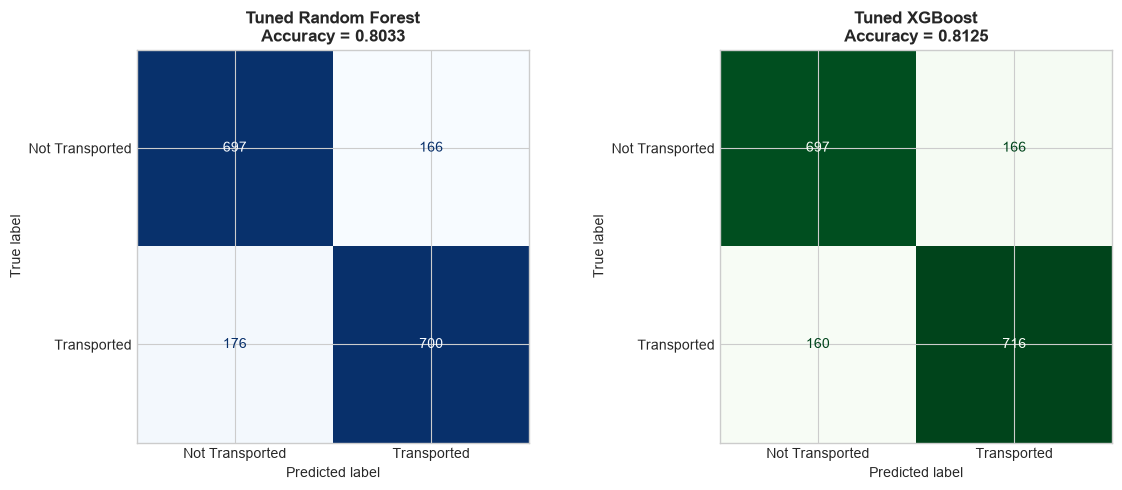

In [21]:
# ── Confusion Matrices ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_val, rf_tuned_pred)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Not Transported', 'Transported'])
disp_rf.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Tuned Random Forest\nAccuracy = {rf_tuned_acc:.4f}', fontsize=12, fontweight='bold')

cm_xgb = confusion_matrix(y_val, xgb_tuned_pred)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Not Transported', 'Transported'])
disp_xgb.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f'Tuned XGBoost\nAccuracy = {xgb_tuned_acc:.4f}', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

In [22]:
# ── Detailed Classification Reports ───────────────────────────────────────────
print('=== Tuned Random Forest Classification Report ===')
print(classification_report(y_val, rf_tuned_pred, target_names=['Not Transported', 'Transported']))

print('\n=== Tuned XGBoost Classification Report ===')
print(classification_report(y_val, xgb_tuned_pred, target_names=['Not Transported', 'Transported']))

=== Tuned Random Forest Classification Report ===
                 precision    recall  f1-score   support

Not Transported       0.80      0.81      0.80       863
    Transported       0.81      0.80      0.80       876

       accuracy                           0.80      1739
      macro avg       0.80      0.80      0.80      1739
   weighted avg       0.80      0.80      0.80      1739


=== Tuned XGBoost Classification Report ===
                 precision    recall  f1-score   support

Not Transported       0.81      0.81      0.81       863
    Transported       0.81      0.82      0.81       876

       accuracy                           0.81      1739
      macro avg       0.81      0.81      0.81      1739
   weighted avg       0.81      0.81      0.81      1739



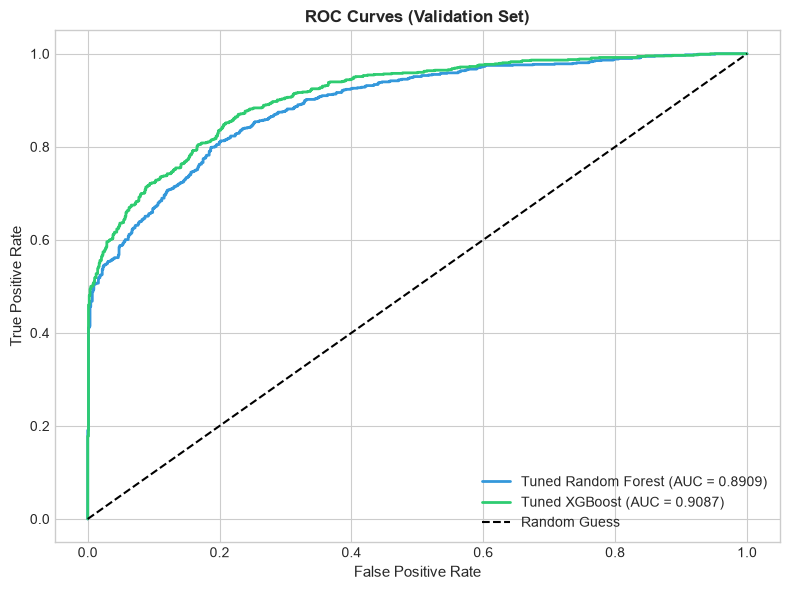

In [23]:
# ── ROC Curves ────────────────────────────────────────────────────────────────
rf_proba = best_rf.predict_proba(X_val)[:, 1]
xgb_proba = best_xgb.predict_proba(X_val)[:, 1]

fpr_rf, tpr_rf, _ = roc_curve(y_val, rf_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_val, xgb_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f'Tuned Random Forest (AUC = {roc_auc_score(y_val, rf_proba):.4f})', color='#3498db', lw=2)
plt.plot(fpr_xgb, tpr_xgb, label=f'Tuned XGBoost (AUC = {roc_auc_score(y_val, xgb_proba):.4f})', color='#2ecc71', lw=2)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess')

plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curves (Validation Set)', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=120, bbox_inches='tight')
plt.show()

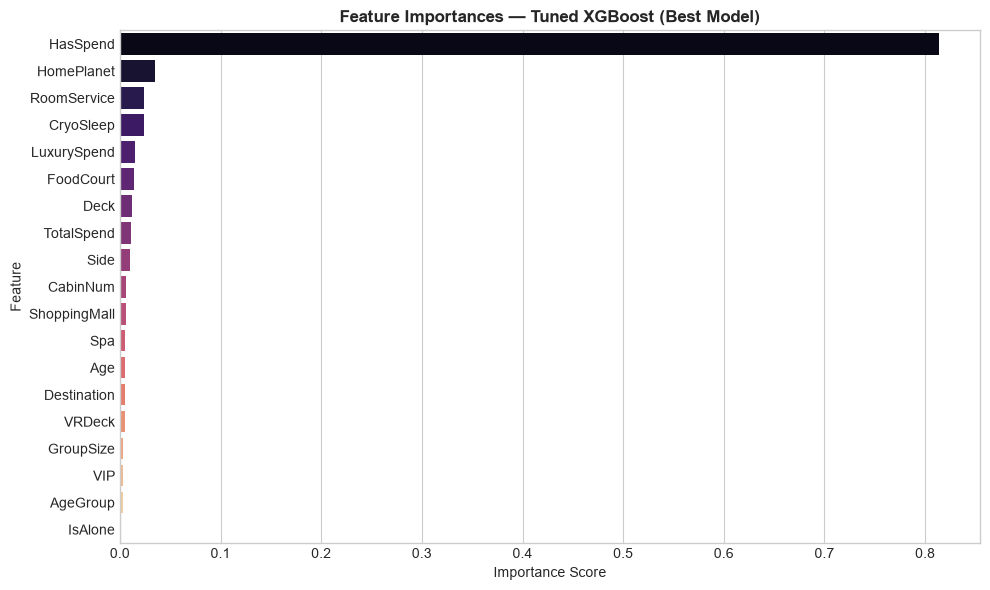

,Feature,Importance
17,HasSpend,0.813821
0,HomePlanet,0.035155
5,RoomService,0.024050
1,CryoSleep,0.023819
16,LuxurySpend,0.014778
6,FoodCourt,0.014099
10,Deck,0.012538
15,TotalSpend,0.010929
12,Side,0.010153
11,CabinNum,0.006212


In [24]:
# ── Best Model Feature Importance ─────────────────────────────────────────────
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': best_xgb.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importances, x='Importance', y='Feature', palette='magma')
plt.title('Feature Importances — Tuned XGBoost (Best Model)', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('best_model_feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()
importances

---
## 12. Test Predictions & Kaggle Submission Generation

In [25]:
# ── Generate Predictions on Test Set using Tuned XGBoost ──────────────────────
final_predictions = best_xgb.predict(X_test_scaled)

# Create submission DataFrame matching Kaggle sample format
submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Transported': final_predictions.astype(bool)
})

# Save to CSV
submission.to_csv('submission.csv', index=False)
print('✅ submission.csv created and saved successfully!')
print(f'Total rows in submission: {len(submission)}')
print('Class distribution in predictions:')
print(submission['Transported'].value_counts())
print(f'Percentage Transported: {submission["Transported"].mean():.2%}')
submission.head(10)

✅ submission.csv created and saved successfully!
Total rows in submission: 4277
Class distribution in predictions:
Transported
True     2165
False    2112
Name: count, dtype: int64
Percentage Transported: 50.62%


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
5,0027_01,True
6,0029_01,True
7,0032_01,True
8,0032_02,True
9,0033_01,True


In [26]:
# ── Verification against Sample Submission ────────────────────────────────────
sample = pd.read_csv('sample_submission.csv')
assert len(submission) == len(sample), 'Row count mismatch with sample submission!'
assert list(submission.columns) == list(sample.columns), 'Column mismatch!'
assert (submission['PassengerId'] == sample['PassengerId']).all(), 'PassengerId order mismatch!'
print('All verification checks passed perfectly! Ready for Kaggle upload! 🎯')

All verification checks passed perfectly! Ready for Kaggle upload! 🎯
